# 07 — Statistics & A/B Testing
## Interview-Oriented Notes + Practical Code

**Goal:** know when a difference is real and when it is noise. You need this whether you compare two models,
two prompts or two versions of a product.

Topics:
- Population, sample, Central Limit Theorem
- Standard error and confidence intervals
- Bootstrap confidence intervals (for any metric)
- Hypothesis testing: p-value, Type I / Type II errors, power
- Which test to use when
- A/B test design: metric, randomization unit, sample size
- A/B test analysis: SRM check, z-test, lift with a confidence interval
- Pitfalls: peeking, multiple testing, novelty effect, Simpson's paradox
- Comparing two models on the same test set (McNemar, paired bootstrap)
- Offline vs online evaluation (and how this carries over to LLM evals)
- Interview cheat sheet

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize, proportion_confint
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# NumPy 2.2 + Apple Accelerate prints harmless "encountered in matmul" RuntimeWarnings
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

rng = np.random.default_rng(42)

# 1. WHY STATISTICS?

Every evaluation is done on a **sample**: a test set, or a few weeks of users.

> Model B scores 0.83 and model A scores 0.81 on 500 test examples. Is B really better, or did it get lucky with these 500?

Statistics answers this question with:
- **Confidence interval:** the range the true value probably lies in
- **Hypothesis test:** how surprising this difference would be if there were no real difference

**Interview:** "A single number from an evaluation is an estimate, so I always report it with a confidence interval,
and I use a significance test before I call one model better than another."

# 2. POPULATION, SAMPLE, CENTRAL LIMIT THEOREM

- **Population:** all possible data (all future users, all future emails)
- **Sample:** what we actually observed
- **Statistic:** a number computed from the sample (mean, accuracy, conversion rate)

**Central Limit Theorem (CLT):** if you take many samples of size n and compute each one's mean,
those means are approximately **normally distributed**, whatever the shape of the population, once n is large enough (about 30 or more).
Their spread is the **standard error**: σ / √n.

This is why z-tests and t-tests work on means and proportions.

Population mean = 10.00, std = 10.00

n=  5: std of sample means = 4.501   σ/√n = 4.471
n= 30: std of sample means = 1.824   σ/√n = 1.825
n=200: std of sample means = 0.704   σ/√n = 0.707


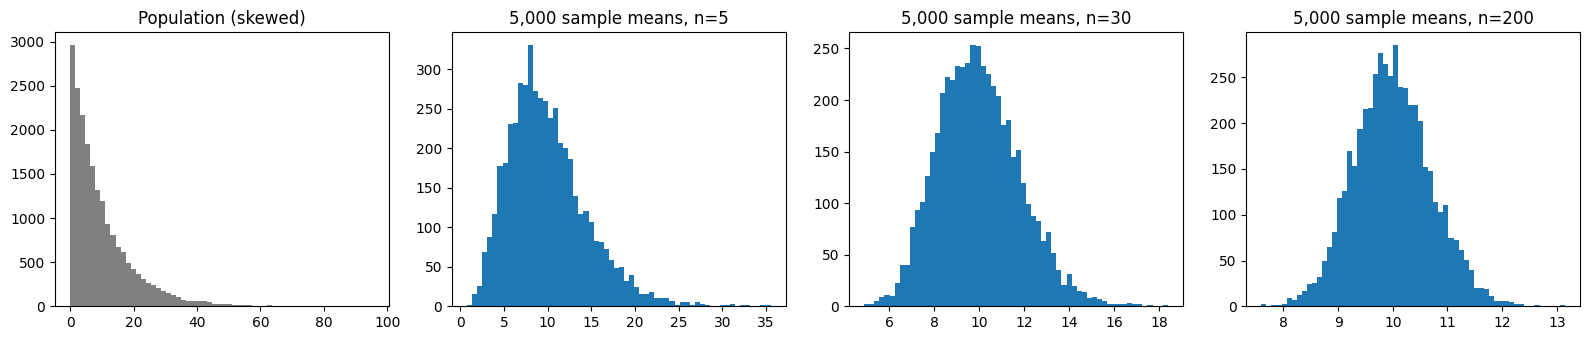

In [2]:
population = rng.exponential(scale=10, size=1_000_000)   # skewed, like order values
print(f"Population mean = {population.mean():.2f}, std = {population.std():.2f}\n")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].hist(population[:20_000], bins=60, color="gray")
axes[0].set_title("Population (skewed)")

for ax, n in zip(axes[1:], [5, 30, 200]):
    sample_means = rng.choice(population, size=(5_000, n)).mean(axis=1)
    ax.hist(sample_means, bins=60)
    ax.set_title(f"5,000 sample means, n={n}")
    print(f"n={n:>3}: std of sample means = {sample_means.std():.3f}   σ/√n = {population.std() / np.sqrt(n):.3f}")

plt.tight_layout()
plt.show()

Observations:
- With n=5 the sample means are still skewed. By n=30 they look normal.
- The spread shrinks as σ/√n: **to halve the uncertainty you need 4× the data.**

# 3. STANDARD ERROR & CONFIDENCE INTERVALS

Standard error (SE) = how much a statistic varies from sample to sample.

| Statistic | Standard error |
|---|---|
| Mean | σ / √n |
| Proportion (accuracy, conversion rate) | √( p(1−p) / n ) |

**95% confidence interval** = estimate ± 1.96 × SE

Correct meaning: if we repeated the experiment many times, about 95% of the intervals built this way would contain the true value.

Wrong meaning: "there is a 95% probability that the true value is in this interval". Interviewers sometimes check this.

In [3]:
n_test = 200
n_correct = 170                       # the model got 170 of 200 test examples right
acc = n_correct / n_test
se = np.sqrt(acc * (1 - acc) / n_test)

print(f"Accuracy = {acc:.3f}   SE = {se:.4f}")
print(f"95% CI (normal approximation) = [{acc - 1.96 * se:.3f}, {acc + 1.96 * se:.3f}]")

low, high = proportion_confint(n_correct, n_test, alpha=0.05, method="wilson")
print(f"95% CI (Wilson, better for small n or p near 0/1) = [{low:.3f}, {high:.3f}]")

Accuracy = 0.850   SE = 0.0252
95% CI (normal approximation) = [0.801, 0.899]
95% CI (Wilson, better for small n or p near 0/1) = [0.794, 0.893]


In [4]:
# How big must a test set be? CI half-width for an 85%-accurate model
rows = []
for n in [100, 500, 1_000, 5_000, 20_000]:
    half_width = 1.96 * np.sqrt(0.85 * 0.15 / n)
    rows.append({"test examples": n, "95% CI": f"85.0% ± {half_width:.1%}"})
pd.DataFrame(rows)

,test examples,95% CI
0,100,85.0% ± 7.0%
1,500,85.0% ± 3.1%
2,1000,85.0% ± 2.2%
3,5000,85.0% ± 1.0%
4,20000,85.0% ± 0.5%


**Takeaway:** on 100 test examples, an 85% accuracy could really be anywhere from about 78% to 92%.
A 1-point gain only becomes visible with thousands of examples. The same holds for LLM eval sets:
50 hand-written questions cannot show a 2% improvement.

# 4. BOOTSTRAP CONFIDENCE INTERVALS

Many metrics have no simple SE formula: F1, AUC, median, p95 latency.

**Bootstrap:**
1. Resample the test set **with replacement**, keeping the same size n
2. Recompute the metric on the resample
3. Repeat about 2,000 times
4. The 2.5th and 97.5th percentiles of those values give a 95% CI

It works for any metric, so it is the default tool for evaluation reports.

In [5]:
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

model_a = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
pred_a = model_a.predict(X_test)


def bootstrap_ci(y_true, y_pred, metric, n_boot=2_000, seed=0):
    r = np.random.default_rng(seed)
    n = len(y_true)
    scores = np.empty(n_boot)
    for i in range(n_boot):
        idx = r.integers(0, n, n)              # n row indices drawn WITH replacement
        scores[i] = metric(y_true[idx], y_pred[idx])
    return np.percentile(scores, [2.5, 97.5])


f1 = f1_score(y_test, pred_a)
low, high = bootstrap_ci(y_test, pred_a, f1_score)
print(f"F1 = {f1:.3f}   95% bootstrap CI = [{low:.3f}, {high:.3f}]   (n_test = {len(y_test)})")

F1 = 0.991   95% bootstrap CI = [0.976, 1.000]   (n_test = 171)


# 5. HYPOTHESIS TESTING

| Term | Meaning |
|---|---|
| H₀ (null hypothesis) | No difference (B = A) |
| H₁ (alternative) | There is a difference |
| α (significance level) | Accepted false-positive rate, usually 0.05 |
| p-value | Probability of a result at least this extreme **if H₀ were true** |
| Type I error | False positive: we say "B is better" when it isn't (probability α) |
| Type II error | False negative: we miss a real improvement (probability β) |
| Power = 1 − β | Probability of detecting a real effect, usually 0.8 |

Decision rule: if p < α, reject H₀.

The p-value is **not** the probability that H₀ is true, and it is **not** the size of the effect.

Below: when there is no real difference (an "A/A test"), about 5% of tests still come out "significant". That 5% is α.

A/A tests with p < 0.05: 5.7%   (expected ≈ 5%)


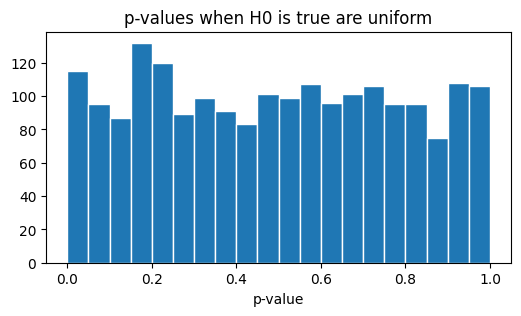

In [6]:
p_values = np.array([
    stats.ttest_ind(rng.normal(100, 15, 200), rng.normal(100, 15, 200), equal_var=False).pvalue
    for _ in range(2_000)                       # both groups come from the SAME distribution: H0 is true
])
print(f"A/A tests with p < 0.05: {np.mean(p_values < 0.05):.1%}   (expected ≈ 5%)")

plt.figure(figsize=(6, 3))
plt.hist(p_values, bins=20, edgecolor="white")
plt.title("p-values when H0 is true are uniform")
plt.xlabel("p-value")
plt.show()

# 6. WHICH TEST WHEN?

| Question | Data | Test | Python |
|---|---|---|---|
| Conversion rate A vs B | Proportions | Two-proportion z-test | `proportions_ztest` |
| Mean revenue A vs B | Continuous, large n | Welch's t-test | `stats.ttest_ind(equal_var=False)` |
| Skewed or outliers, small n | Continuous | Mann-Whitney U | `stats.mannwhitneyu` |
| Same users before / after | Paired continuous | Paired t-test | `stats.ttest_rel` |
| Counts across categories | Contingency table | Chi-square | `stats.chi2_contingency` |
| Two classifiers, same test set | Paired right/wrong | McNemar | `statsmodels mcnemar` |
| Any metric, no formula | Anything | Bootstrap / permutation | NumPy |

Welch's t-test does not assume equal variances, so use it as the default t-test.
Mann-Whitney tests whether values from one group tend to be larger. It does not test means.

In [7]:
# Revenue per user is skewed: most users spend little, a few spend a lot
rev_a = rng.lognormal(mean=3.0, sigma=1.0, size=1_000)
rev_b = rng.lognormal(mean=3.1, sigma=1.0, size=1_000)     # B really is ~10% higher

print(f"Mean revenue A = {rev_a.mean():.1f}, B = {rev_b.mean():.1f}")
print(f"Welch t-test   p = {stats.ttest_ind(rev_a, rev_b, equal_var=False).pvalue:.4f}")
print(f"Mann-Whitney U p = {stats.mannwhitneyu(rev_a, rev_b, alternative='two-sided').pvalue:.4f}")

Mean revenue A = 35.3, B = 37.0
Welch t-test   p = 0.4332
Mann-Whitney U p = 0.0318


The effect is real, but the t-test misses it: a few very large values inflate the variance.
Mann-Whitney works on ranks, so it is not thrown off by outliers, and it detects the effect.
For skewed metrics such as revenue, also consider a log transform, capping extreme values, or a bootstrap CI.

# 7. A/B TEST — DESIGN

1. **Hypothesis:** "The new ranking model increases click-through rate"
2. **One primary metric** (CTR) plus **guardrail metrics** that must not get worse (latency, error rate, unsubscribes)
3. **Randomization unit:** usually the *user*, not the request, so one person never sees both versions
4. **MDE (minimum detectable effect):** the smallest improvement worth detecting, e.g. +1 percentage point
5. **α = 0.05, power = 0.8 → sample size**
6. **Duration:** whole weeks, to cover weekday/weekend patterns; decide it **before** starting
7. Run → check data quality (SRM) → analyze → decide

Sample size grows with 1 / MDE²: **halving the MDE needs 4× the users.**

In [8]:
baseline = 0.10          # current conversion rate
target = 0.11            # MDE: +1 percentage point

effect = proportion_effectsize(target, baseline)   # Cohen's h
n_per_group = NormalIndPower().solve_power(effect_size=effect, alpha=0.05, power=0.8, ratio=1.0)
print(f"statsmodels: users needed per group = {np.ceil(n_per_group):,.0f}")

# Same idea by hand: n ≈ (z_α/2 + z_β)² · [p1(1−p1) + p2(1−p2)] / (p2 − p1)²
z_alpha, z_beta = stats.norm.ppf(0.975), stats.norm.ppf(0.8)
n_manual = (z_alpha + z_beta) ** 2 * (baseline * (1 - baseline) + target * (1 - target)) / (target - baseline) ** 2
print(f"formula:     users needed per group = {np.ceil(n_manual):,.0f}")

statsmodels: users needed per group = 14,745
formula:     users needed per group = 14,749


In [9]:
rows = []
for mde in [0.005, 0.01, 0.02, 0.05]:
    h = proportion_effectsize(baseline + mde, baseline)
    n = NormalIndPower().solve_power(effect_size=h, alpha=0.05, power=0.8)
    rows.append({"baseline": f"{baseline:.0%}", "MDE (absolute)": f"+{mde:.1%}", "users per group": f"{np.ceil(n):,.0f}"})
pd.DataFrame(rows)

,baseline,MDE (absolute),users per group
0,10%,+0.5%,"57,756"
1,10%,+1.0%,"14,745"
2,10%,+2.0%,"3,835"
3,10%,+5.0%,681


# 8. A/B TEST — ANALYSIS

Simulated experiment: 30,000 users are split at random; control converts at 10% and treatment at 11% (a real +1 point effect).

**Step 1: Sample Ratio Mismatch (SRM) check.** We asked for 50/50. If the split is far from 50/50,
randomization or logging is broken and **no other result can be trusted**.

**Step 2: Two-proportion z-test** plus a **confidence interval for the lift**.

In [10]:
n_users = 30_000
n_treatment = rng.binomial(n_users, 0.5)          # each user is assigned by a fair coin flip
n_control = n_users - n_treatment
conv_control = rng.binomial(n_control, 0.10)
conv_treatment = rng.binomial(n_treatment, 0.11)

srm_p = stats.chisquare([n_control, n_treatment]).pvalue
print(f"Split: control {n_control:,} / treatment {n_treatment:,}   SRM p = {srm_p:.3f}")
print("SRM OK\n" if srm_p > 0.001 else "SRM FAILED: stop and debug the assignment\n")

z_stat, p_value = proportions_ztest([conv_treatment, conv_control], [n_treatment, n_control])
p_c, p_t = conv_control / n_control, conv_treatment / n_treatment
diff = p_t - p_c
se_diff = np.sqrt(p_c * (1 - p_c) / n_control + p_t * (1 - p_t) / n_treatment)
ci_low, ci_high = diff - 1.96 * se_diff, diff + 1.96 * se_diff

print(f"Control {p_c:.2%}   Treatment {p_t:.2%}")
print(f"Absolute lift {diff:+.2%}   95% CI [{ci_low:+.2%}, {ci_high:+.2%}]")
print(f"Relative lift {diff / p_c:+.1%}")
print(f"z = {z_stat:.2f}   p = {p_value:.5f}")

Split: control 14,949 / treatment 15,051   SRM p = 0.556
SRM OK

Control 9.59%   Treatment 11.08%
Absolute lift +1.48%   95% CI [+0.79%, +2.17%]
Relative lift +15.5%
z = 4.22   p = 0.00002


In [11]:
# What a broken split looks like: 15,000 vs 14,400 users when 50/50 was requested
print(f"SRM p = {stats.chisquare([15_000, 14_400]).pvalue:.2e}  → randomization or logging bug")

SRM p = 4.67e-04  → randomization or logging bug


**Decision checklist:**
- SRM passed?
- p < α **and** the whole CI is above 0? → the effect is statistically significant
- Is the lift large enough to matter (**practical significance**)? +0.01% can be significant with 10M users and still not be worth the engineering cost
- Guardrail metrics unharmed?
- Ship, iterate, or stop

# 9. PITFALLS

### 9.1 Peeking
Checking the p-value every day and stopping as soon as p < 0.05 **inflates the false-positive rate far above 5%**.
Fix: fix the sample size in advance, or use sequential testing methods built for repeated looks.

In [12]:
def peeking_false_positive_rate(n_experiments=1_000, n_looks=20, users_per_look=500, p=0.10, seed=1):
    r = np.random.default_rng(seed)
    false_positives = 0
    for _ in range(n_experiments):
        a = r.binomial(1, p, n_looks * users_per_look)
        b = r.binomial(1, p, n_looks * users_per_look)      # A/A test: no real difference
        for look in range(1, n_looks + 1):
            n = look * users_per_look
            _, pv = proportions_ztest([a[:n].sum(), b[:n].sum()], [n, n])
            if pv < 0.05:                                    # "significant!" → stop early
                false_positives += 1
                break
    return false_positives / n_experiments


print("False-positive rate, one look at the end : ~5% (by design)")
print(f"False-positive rate, peeking 20 times    : {peeking_false_positive_rate():.1%}")

False-positive rate, one look at the end : ~5% (by design)


False-positive rate, peeking 20 times    : 25.1%


### 9.2 Multiple testing
Test 20 metrics at α = 0.05 and the chance of at least one false positive is 1 − 0.95²⁰ ≈ **64%**.

- **Bonferroni:** use α / m. Simple and strict.
- **Benjamini-Hochberg (BH):** controls the *false discovery rate*. Less strict; common when there are many metrics.

In [13]:
p_vals = np.concatenate([rng.uniform(0, 1, 18), [0.001, 0.004]])     # 18 metrics with no effect, 2 real effects

print(f"P(≥1 false positive in 20 tests) = {1 - 0.95 ** 20:.0%}")
print(f"Raw p < 0.05     : {np.sum(p_vals < 0.05)} metrics flagged")
for method in ["bonferroni", "fdr_bh"]:
    reject = multipletests(p_vals, alpha=0.05, method=method)[0]
    print(f"{method:<11}      : {reject.sum()} metrics flagged")

P(≥1 false positive in 20 tests) = 64%
Raw p < 0.05     : 2 metrics flagged
bonferroni       : 1 metrics flagged
fdr_bh           : 2 metrics flagged


### 9.3 Other pitfalls
- **Novelty / primacy effect:** users click on something just because it is new, or resist it at first. Run long enough to see past this.
- **Interference / network effects:** treatment users affect control users (marketplaces, social apps). Randomize by region or cluster instead.
- **Simpson's paradox:** B wins in every segment but loses overall, because the segment mix differs. Check the segments.
- **Underpowered test:** "not significant" does **not** mean "no effect". The sample may have been too small to see it.
- **Wrong randomization unit:** randomizing per request while measuring per user breaks the independence assumption.

# 10. COMPARING TWO MODELS ON THE SAME TEST SET

Both models predict the **same** examples, so the results are **paired**.
Comparing two separate confidence intervals wastes that information and is too conservative.

- **McNemar's test:** looks only at the examples where the models disagree
- **Paired bootstrap:** resample row indices once and score both models on the same resampled rows

**This is the same setup you will use to compare two prompts or two LLMs on an eval set in the GenAI phase.**

In [14]:
model_b = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)
pred_b = model_b.predict(X_test)

correct_a = pred_a == y_test
correct_b = pred_b == y_test
print(f"Accuracy A (LogReg)       = {correct_a.mean():.3f}")
print(f"Accuracy B (RandomForest) = {correct_b.mean():.3f}\n")

table = (
    pd.crosstab(pd.Series(correct_a, name="A correct"), pd.Series(correct_b, name="B correct"))
    .reindex(index=[True, False], columns=[True, False], fill_value=0)
)
print(table, "\n")
print(f"McNemar exact p = {mcnemar(table.values, exact=True).pvalue:.3f}")

Accuracy A (LogReg)       = 0.988
Accuracy B (RandomForest) = 0.942

B correct  True   False
A correct              
True         160      9
False          1      1 

McNemar exact p = 0.021


In [15]:
def paired_bootstrap_diff(correct_a, correct_b, n_boot=5_000, seed=0):
    r = np.random.default_rng(seed)
    idx = r.integers(0, len(correct_a), size=(n_boot, len(correct_a)))   # the SAME rows for both models
    diffs = correct_b[idx].mean(axis=1) - correct_a[idx].mean(axis=1)
    return np.percentile(diffs, [2.5, 97.5])


low, high = paired_bootstrap_diff(correct_a, correct_b)
print(f"Accuracy B − A = {correct_b.mean() - correct_a.mean():+.3f}   95% CI [{low:+.3f}, {high:+.3f}]")
print("CI contains 0 → no evidence that one model is better" if low <= 0 <= high else "CI excludes 0 → real difference")

Accuracy B − A = -0.047   95% CI [-0.082, -0.012]
CI excludes 0 → real difference


# 11. OFFLINE vs ONLINE EVALUATION

| | Offline | Online (A/B test) |
|---|---|---|
| Data | Held-out test set | Real users |
| Metric | Proxy (F1, AUC, eval score) | Business metric (conversion, retention) |
| Speed and cost | Minutes, cheap | Weeks, risky |
| Answers | "Is the model better on past data?" | "Does it help users now?" |

A good offline gain does not guarantee an online gain (proxy mismatch, feedback loops, distribution shift).

Typical rollout (see `6-ml-deployments`):

```text
Offline eval → Shadow (no user impact) → Canary (1–5%) → A/B test (50/50) → Full rollout
```

**For LLM applications:**
- Offline: golden eval set + LLM-as-judge, compared with the paired tests above
- Online: thumbs up/down, task completion, escalation rate, cost and latency as guardrails

# 12. COMMON MISTAKES

1. Reporting a metric without a confidence interval.
2. Reading the p-value as the probability that H₀ is true.
3. Peeking and stopping early.
4. Testing many metrics or segments without correction.
5. Skipping the SRM check.
6. Confusing statistical significance with practical significance.
7. Treating "not significant" as "no effect".
8. Using unpaired tests to compare models on the same test set.
9. Changing the primary metric after seeing the results.
10. Running the test for a few days only (weekly seasonality, novelty effect).

# 13. INTERVIEW CHEAT SHEET

### What is a p-value?
The probability of seeing data at least this extreme if the null hypothesis were true.

### What is a 95% confidence interval?
A range built so that, over many repeated experiments, 95% of such ranges contain the true value.

### Type I vs Type II error?
Type I = false positive (probability α). Type II = false negative (probability β). Power = 1 − β.

### What decides the sample size?
Baseline rate, MDE, α and power. n grows with 1 / MDE².

### How do you design an A/B test?
Hypothesis → primary + guardrail metrics → randomization unit → MDE → sample size and duration (fixed in advance) → SRM check → test → decision.

### Why not peek?
Repeated looks inflate the false-positive rate. Fix the sample size in advance or use sequential testing.

### What is SRM?
Sample Ratio Mismatch: the observed split differs from the planned split. It signals a bug, so results cannot be trusted.

### Statistical vs practical significance?
Statistical: unlikely to be noise. Practical: big enough to be worth acting on.

### How to compare two models on one test set?
Paired tests: McNemar for right/wrong outcomes, paired bootstrap for any metric.

### When to use the bootstrap?
When the metric has no simple standard-error formula (F1, AUC, median, p95 latency).

### Many metrics tested at once?
Correct for multiple testing: Bonferroni (strict) or Benjamini-Hochberg (false discovery rate).

# 14. FINAL MENTAL MODEL

```text
            Observed difference (B − A)
                       |
          Is it bigger than the noise?
                       |
        ┌──────────────┴──────────────┐
        ↓                             ↓
  Confidence interval           Hypothesis test
  (± 1.96·SE or bootstrap)      (p-value vs α)
        |                             |
        └──────────────┬──────────────┘
                       ↓
     Design checks: power / sample size, SRM,
     no peeking, multiple-testing correction
                       ↓
     Practical significance + guardrails
                       ↓
               Ship / iterate / stop
```

Remember:

- SE shrinks with √n → 4× data for half the uncertainty
- Bootstrap → CI for any metric
- Same test set → paired test
- A/B test → fix the sample size first, check SRM, don't peek